# Experiment 1: K-Means Clustering on Old Faithful Geyser

**Aim:** Apply K-Means clustering to group Old Faithful geyser observations using eruption duration and waiting time between eruptions.

In [1]:
# If Seaborn is not installed, run: %pip install seaborn
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

## 1. Load the dataset

In [2]:
geyser = sns.load_dataset('geyser')
geyser = geyser[['duration', 'waiting']].dropna()
print('Dataset shape:', geyser.shape)
geyser.head()

Dataset shape: (272, 2)


,duration,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


## 2. Visualize the data

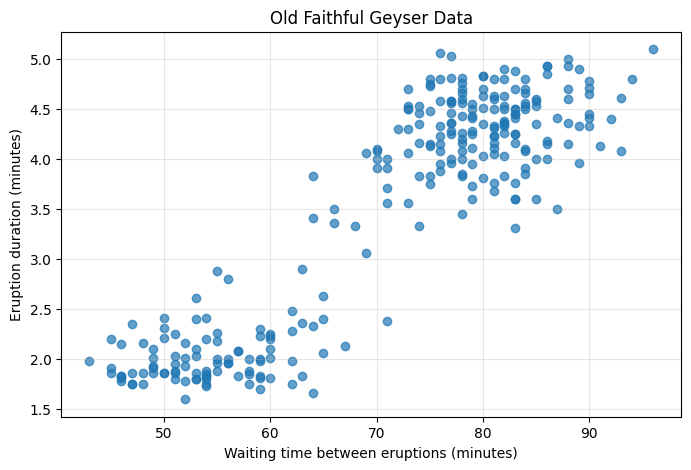

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(geyser['waiting'], geyser['duration'], alpha=0.7)
plt.xlabel('Waiting time between eruptions (minutes)')
plt.ylabel('Eruption duration (minutes)')
plt.title('Old Faithful Geyser Data')
plt.grid(True, alpha=0.3)
plt.show()

## 3. Scale features and find K using the elbow method

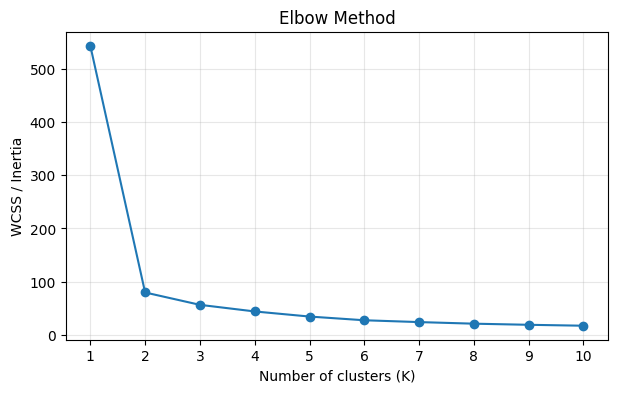

In [4]:
X = geyser[['duration', 'waiting']].to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.show()

## 4. Apply K-Means with K = 2

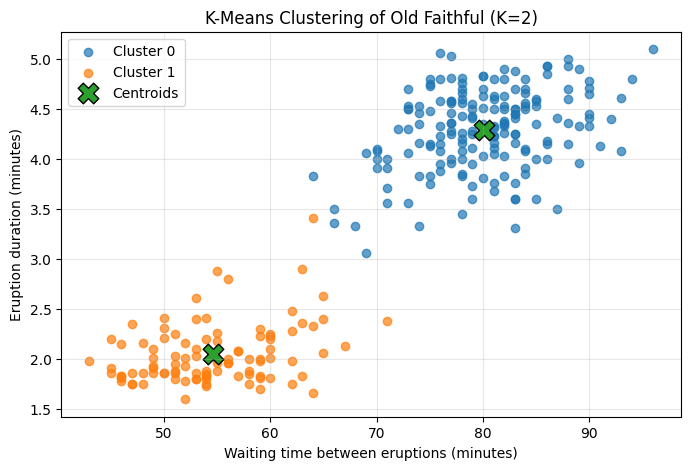

Cluster counts:
cluster
0    174
1     98
Name: count, dtype: int64

Centroids (duration, waiting):
   duration_minutes  waiting_minutes
0          4.296328        80.080460
1          2.052204        54.591837

Silhouette score: 0.745


In [5]:
kmeans = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
geyser['cluster'] = kmeans.fit_predict(X_scaled)
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5))
for cluster_id in sorted(geyser['cluster'].unique()):
    group = geyser[geyser['cluster'] == cluster_id]
    plt.scatter(group['waiting'], group['duration'], label=f'Cluster {cluster_id}', alpha=0.7)
plt.scatter(centers[:, 1], centers[:, 0], marker='X', s=220, edgecolor='black', label='Centroids')
plt.xlabel('Waiting time between eruptions (minutes)')
plt.ylabel('Eruption duration (minutes)')
plt.title('K-Means Clustering of Old Faithful (K=2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print('Cluster counts:')
print(geyser['cluster'].value_counts().sort_index())
print('\nCentroids (duration, waiting):')
print(pd.DataFrame(centers, columns=['duration_minutes', 'waiting_minutes']))
print('\nSilhouette score:', round(silhouette_score(X_scaled, geyser['cluster']), 3))

## Result
K-Means grouped the geyser observations into two clusters based on eruption duration and waiting time. The scatter plot shows the cluster assignments and centroid locations.